# 01 — Does supervision make predictive information more compact?

**Question.** Compare training-only PLS, PCA and original features with validation-selected complexity.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_supervised_reduction.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.supervised_reduction import inputs,read_table,OUT
from src.injury_analysis.supervised_workflow import ensure_stage
from src.injury_analysis import supervised_plots as plots
FORCE_RECOMPUTE=False
a,events,spec,matches=inputs()
pd.set_option('display.max_columns',18)


## Existing cohorts and comparison design
Retain the seven category-specific 30-day targets, starters and relievers, observed-follow-up negatives, exclusions and 60-day temporal embargo. Train through 2021; validation 2022–2023; previously examined test 2024–2025. Every method within a representation uses identical rows. No outcome or feature screening outside training contributes to the learned axes.

Four source representations reuse existing definitions: original 62 features; 13 profile fields (eight prior means + five slow context variables); eight current pitcher-relative departures; and the combined 21 fields. Workload remains in the original-feature comparator rather than being forced into the profile/departure split. Current measurements describe an already completed outing.

**PLS** fits continuous predictors to the binary training outcome. We orthonormalize each nested PLS span with QR and use the same L2 logistic C=1 as PCA and unreduced models. QR preserves each supervised subspace while avoiding an arbitrary axis-scale change to the regularization penalty. It does not whiten scores. Raw PLS regression values are not used as probabilities. All imputation/scaling fits on training only.

Binary context and training-observed missingness flags pass through for both projection methods. Thus *k components is not k total model columns*. The context/availability-only diagnostic tests what survives without any continuous projection. A full-span completion control should approximately reproduce original predictions.

In [2]:
ensure_stage('prediction',a,events,spec,matches,force=FORCE_RECOMPUTE)
display(read_table('validation_selection'))
display(read_table('selected_performance').query("block=='Original 62' and variant=='Unreduced'")[[
 'category','partition','rows','positive_rows','represented_events','pitchers','prevalence']])
display(read_table('full_span_control').groupby('block')[['max_score_difference','ap_difference']].max())

Using verified prediction artifacts.


,category,block,condition,method,selected_components,continuous_features,passthrough_columns,design_columns,validation_ap,plateau_components,plateau_cutoff_ap,training_variance_retained,pca_variance_90_components,train_rows,train_positive_rows,train_positive_events
0,Elbow / UCL,Original 62,Primary,PCA,30,60,47,77,0.028498,30.0,0.028192,0.900213,30,81145,1441,223
1,Elbow / UCL,Original 62,Primary,PLS,10,60,47,57,0.030012,10.0,0.029631,0.417808,30,81145,1441,223
2,Elbow / UCL,Profile,Primary,PCA,12,12,10,22,0.029099,12.0,0.028764,1.000000,9,81145,1441,223
3,Elbow / UCL,Profile,Primary,PLS,5,12,10,15,0.029331,5.0,0.028984,0.490758,9,81145,1441,223
4,Elbow / UCL,Departure,Primary,PCA,8,8,8,16,0.026857,7.0,0.026633,1.000000,7,81145,1441,223
5,Elbow / UCL,Departure,Primary,PLS,2,8,8,10,0.026877,2.0,0.026653,0.247988,7,81145,1441,223
6,Elbow / UCL,Combined,Primary,PCA,20,20,18,38,0.028309,20.0,0.028014,1.000000,16,81145,1441,223
7,Elbow / UCL,Combined,Primary,PLS,5,20,18,23,0.029569,5.0,0.029210,0.315257,16,81145,1441,223
8,Shoulder,Original 62,Primary,PCA,30,60,47,77,0.038333,30.0,0.037783,0.900293,30,81978,2274,350
9,Shoulder,Original 62,Primary,PLS,30,60,47,77,0.044923,20.0,0.044043,0.782149,30,81978,2274,350


,category,partition,rows,positive_rows,represented_events,pitchers,prevalence
0,Elbow / UCL,validation,26796,600,89,783,0.022391
4,Elbow / UCL,test,27665,708,110,789,0.025592
32,Shoulder,validation,26932,736,115,782,0.027328
36,Shoulder,test,27806,849,125,786,0.030533
64,Forearm,validation,26478,282,41,772,0.010650
68,Forearm,test,27236,279,38,779,0.010244
96,Other arm,validation,26423,227,33,775,0.008591
100,Other arm,test,27216,259,38,781,0.009516
128,Trunk / neck,validation,26876,680,103,781,0.025301
132,Trunk / neck,test,27408,451,65,780,0.016455


,max_score_difference,ap_difference
block,,
Combined,2.616151e-04,7.124221e-08
Departure,3.149148e-13,0.000000e+00
Original 62,1.356997e-05,1.924430e-07
Profile,4.030329e-06,1.560301e-06


## Component selection and empirical near-peak behavior
PLS and PCA use the same tested dimensions within each block, augmented with the PCA-90% count learned from training. Pick maximum **validation AP**, breaking ties toward fewer components. Neither test performance nor matched trajectories selects k.

The near-peak summary is the smallest tested k achieving 95% of the best validation AP *gain over prevalence*. A second column asks whether all later tested counts also remain above that threshold. These are descriptive summaries, not confidence-based plateaus. A small gain above chance can be unstable even if its representation is compact. The first axis of a binary supervised learner is not evidence for one underlying biological mechanism.

,category,block,condition,method,selected_components,continuous_features,passthrough_columns,design_columns,validation_ap,...,train_positive_events,sustained_95pct_gain_components,validation_unreduced_ap,validation_passthrough_ap,validation_prevalence,test_ap,test_unreduced_ap,test_passthrough_ap,test_prevalence
0,Elbow / UCL,Original 62,Primary,PCA,30,60,47,77,0.028498,...,223,30.0,0.028415,0.021678,0.022391,0.037415,0.042629,0.031196,0.025592
1,Elbow / UCL,Original 62,Primary,PLS,10,60,47,57,0.030012,...,223,NaN,0.028415,0.021678,0.022391,0.046574,0.042629,0.031196,0.025592
2,Elbow / UCL,Profile,Primary,PCA,12,12,10,22,0.029099,...,223,12.0,0.029100,0.022777,0.022391,0.026197,0.026197,0.026152,0.025592
3,Elbow / UCL,Profile,Primary,PLS,5,12,10,15,0.029331,...,223,12.0,0.029100,0.022777,0.022391,0.025793,0.026197,0.026152,0.025592
4,Elbow / UCL,Departure,Primary,PCA,8,8,8,16,0.026857,...,223,7.0,0.026857,0.022461,0.022391,0.030564,0.030564,0.025572,0.025592
5,Elbow / UCL,Departure,Primary,PLS,2,8,8,10,0.026877,...,223,2.0,0.026857,0.022461,0.022391,0.030547,0.030564,0.025572,0.025592
6,Elbow / UCL,Combined,Primary,PCA,20,20,18,38,0.028309,...,223,20.0,0.028310,0.022729,0.022391,0.029149,0.029149,0.026083,0.025592
7,Elbow / UCL,Combined,Primary,PLS,5,20,18,23,0.029569,...,223,NaN,0.028310,0.022729,0.022391,0.030113,0.029149,0.026083,0.025592
8,Shoulder,Original 62,Primary,PCA,30,60,47,77,0.038333,...,350,30.0,0.044947,0.030247,0.027328,0.048404,0.055919,0.034058,0.030533
9,Shoulder,Original 62,Primary,PLS,30,60,47,77,0.044923,...,350,20.0,0.044947,0.030247,0.027328,0.056104,0.055919,0.034058,0.030533


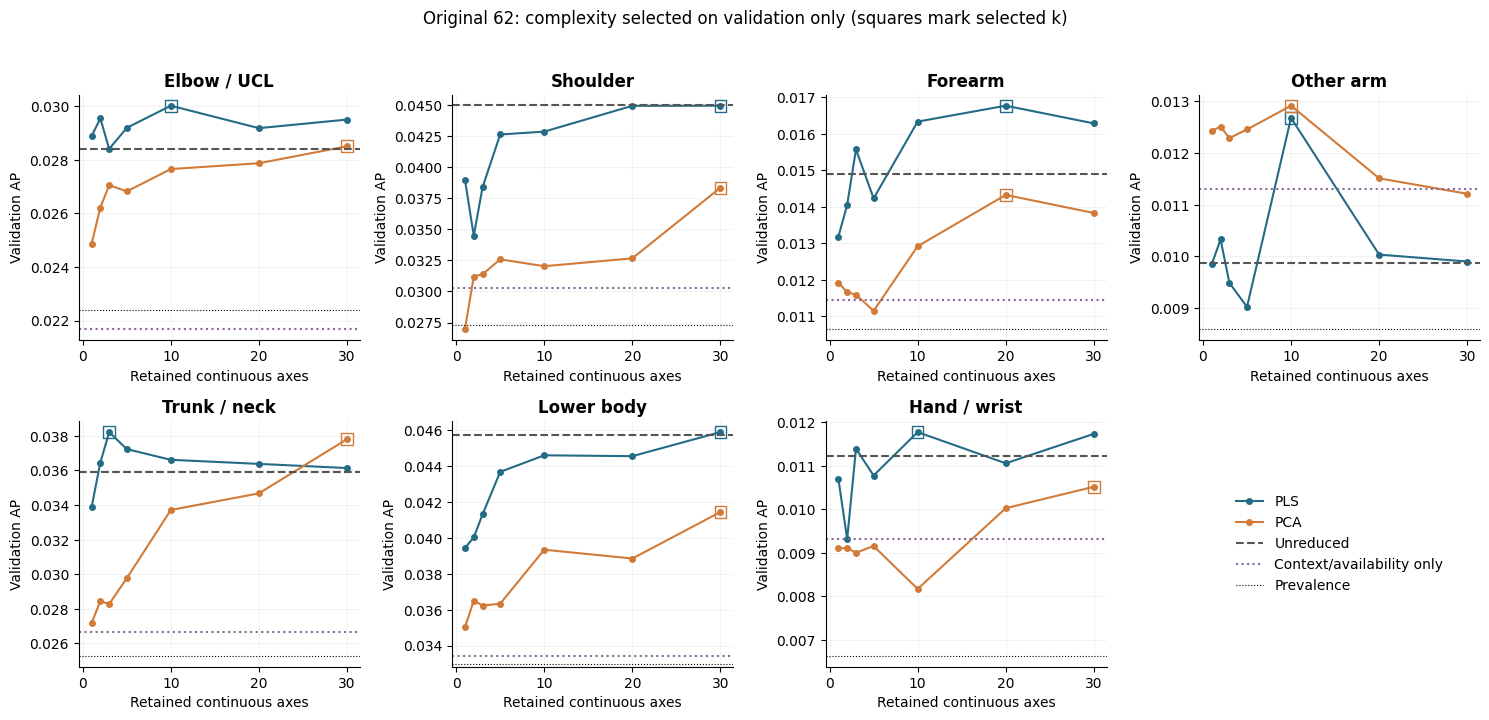

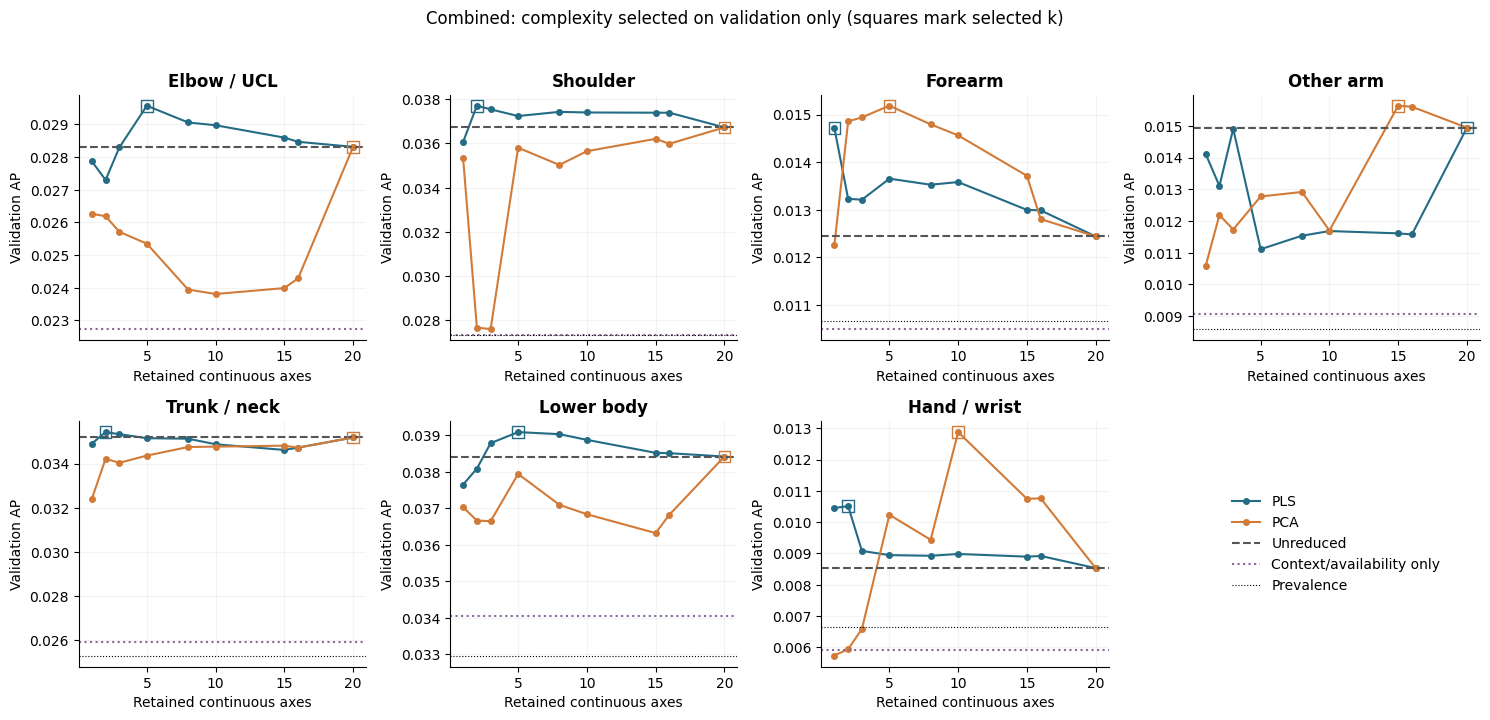

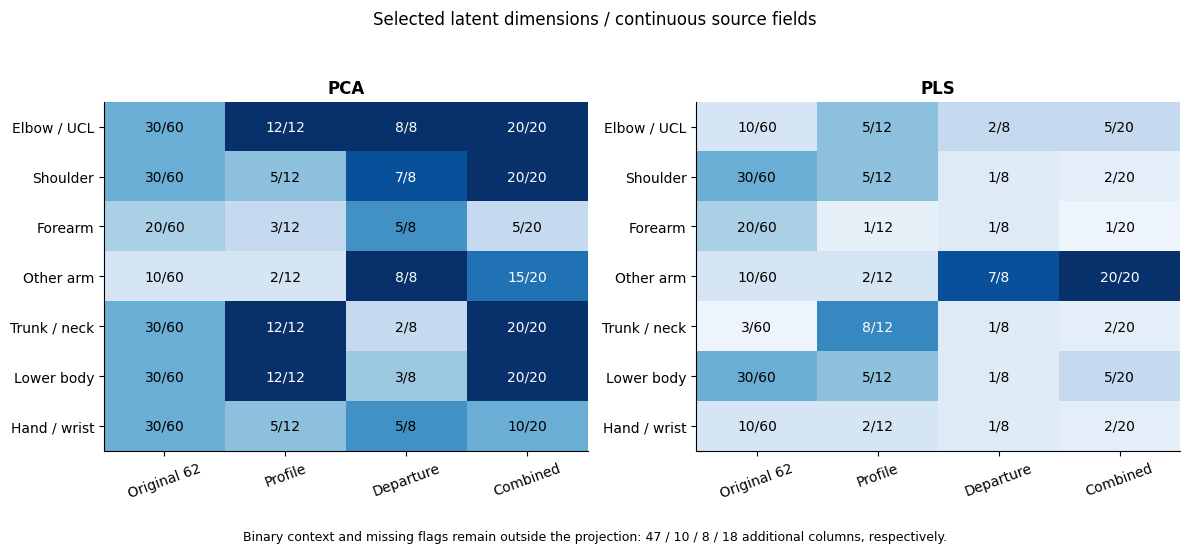

In [3]:
from src.injury_analysis.supervised_report import compression_summary
display(compression_summary())
plots.curve_figure('Original 62');plt.show()
plots.curve_figure('Combined');plt.show()
plots.compression_figure();plt.show()

## Predictive and practical comparisons
Paired intervals resample evaluation pitchers using the established 300 shared draws and condition on trained models and selected k. They do not include tuning uncertainty or correct every multiple comparison. Validation selection makes validation estimates optimistic.

Keep 7–30-day event warnings, all-event denominators and the existing 1%, 2.5%, 5% and 10% alert budgets. A model can improve AP while reducing useful event warnings. Uniform-random expected recall and conditional warning leads are retained. Retrospective top-k alerts do not guarantee a deployable fixed threshold. Brier is total probability error, not calibration alone.

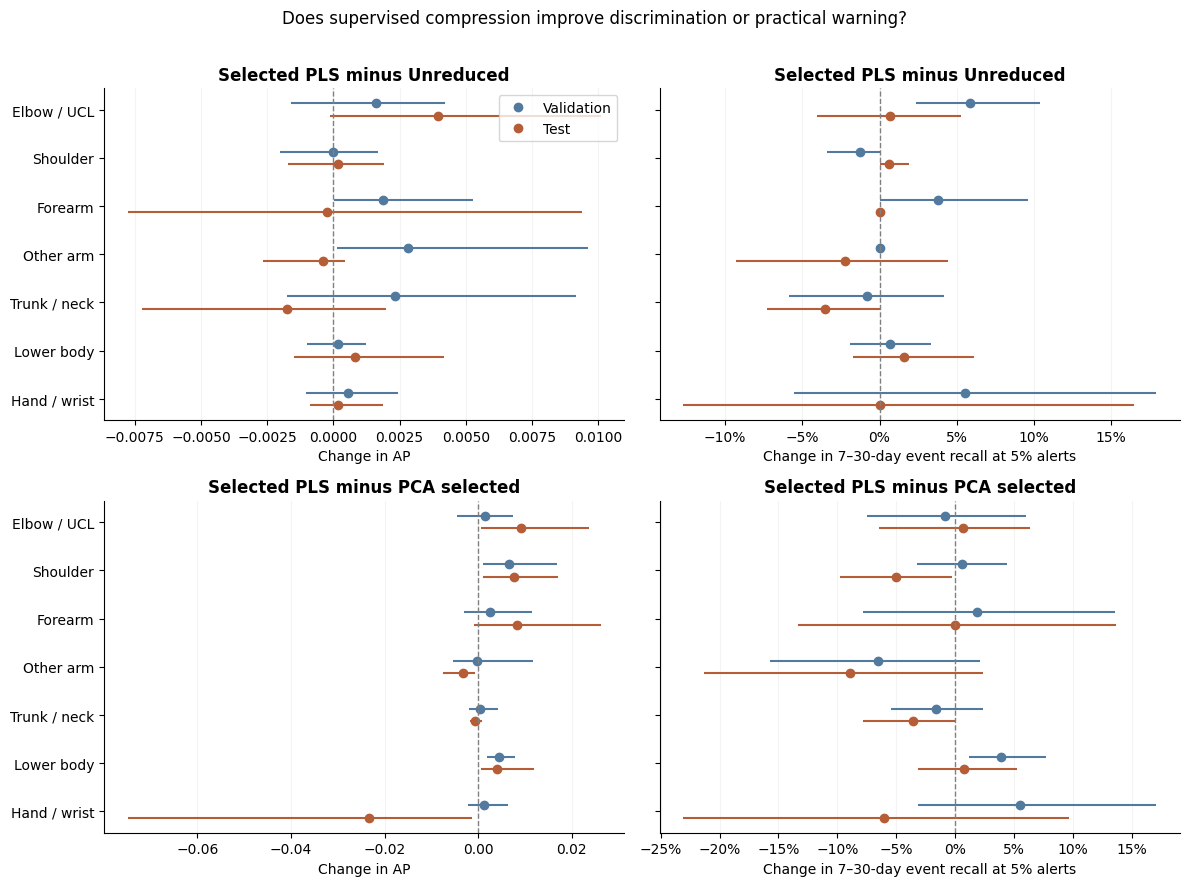

,category,partition,analysis,variant,reference,ap_difference,ap_low,ap_high,brier_difference,...,event_gained_events,event_lost_events,event_shared_detected_events,event_common_lead_mean,event_common_lead_low,event_common_lead_high,event_common_lead_events,event_common_lead_pitchers,block
0,Elbow / UCL,validation,Original 62,PLS selected,Unreduced,0.001596,-0.001605,0.004212,-0.000063,...,7,0,12,-0.500000,-1.750000,0.250000,12,12,Original 62
1,Elbow / UCL,validation,Original 62,PLS selected,PCA selected,0.001514,-0.004571,0.007432,0.000040,...,8,9,11,-0.636364,-2.181818,0.272727,11,11,Original 62
3,Elbow / UCL,test,Original 62,PLS selected,Unreduced,0.003945,-0.000128,0.010098,-0.000043,...,6,5,21,1.428571,-0.072619,3.383333,21,21,Original 62
4,Elbow / UCL,test,Original 62,PLS selected,PCA selected,0.009159,0.000498,0.023560,-0.000089,...,12,11,15,-2.066667,-5.273333,0.133333,15,15,Original 62
24,Shoulder,validation,Original 62,PLS selected,Unreduced,-0.000024,-0.002021,0.001676,-0.000004,...,0,2,23,0.695652,0.000000,2.436364,23,22,Original 62
25,Shoulder,validation,Original 62,PLS selected,PCA selected,0.006590,0.000976,0.016773,-0.000060,...,5,4,18,1.333333,-2.225000,4.751389,18,18,Original 62
27,Shoulder,test,Original 62,PLS selected,Unreduced,0.000185,-0.001706,0.001898,-0.000005,...,1,0,28,0.000000,0.000000,0.000000,28,25,Original 62
28,Shoulder,test,Original 62,PLS selected,PCA selected,0.007700,0.000969,0.016979,-0.000123,...,3,11,26,-0.423077,-2.760096,2.121267,26,23,Original 62
48,Forearm,validation,Original 62,PLS selected,Unreduced,0.001878,0.000039,0.005264,-0.000041,...,2,0,8,0.125000,0.000000,0.375000,8,8,Original 62
49,Forearm,validation,Original 62,PLS selected,PCA selected,0.002442,-0.003008,0.011422,0.000052,...,5,4,5,4.000000,0.000000,9.000000,5,5,Original 62


,category,partition,variant,qualifying_events,observable_events,alerted_events,injury_event_recall,random_expected_event_recall,median_warning_lead_days,false_alerts_per_pitcher_season
2,Elbow / UCL,validation,Unreduced,120,80,12,0.100000,0.155034,16.0,1.071901
6,Elbow / UCL,validation,Context/availability only,120,80,6,0.050000,0.155034,15.0,1.099174
10,Elbow / UCL,validation,PCA selected,120,80,20,0.166667,0.155034,16.0,1.065289
14,Elbow / UCL,validation,PLS selected,120,80,19,0.158333,0.155034,15.0,1.061983
18,Elbow / UCL,test,Unreduced,145,104,26,0.179310,0.157328,17.5,1.090226
22,Elbow / UCL,test,Context/availability only,145,104,17,0.117241,0.157328,20.0,1.113617
26,Elbow / UCL,test,PCA selected,145,104,26,0.179310,0.157328,24.5,1.095238
30,Elbow / UCL,test,PLS selected,145,104,27,0.186207,0.157328,16.0,1.083542
130,Shoulder,validation,Unreduced,161,104,25,0.155280,0.147642,25.0,1.043225
134,Shoulder,validation,Context/availability only,161,104,15,0.093168,0.147642,25.0,1.088113


,block,partition,variant,average_precision,pr_lift,roc_auc,brier_score
32,Original 62,validation,Unreduced,0.044947,1.644710,0.573474,0.026548
33,Original 62,validation,Context/availability only,0.030247,1.106813,0.521674,0.026600
34,Original 62,validation,PCA selected,0.038333,1.402711,0.572150,0.026604
35,Original 62,validation,PLS selected,0.044923,1.643843,0.572899,0.026544
36,Original 62,test,Unreduced,0.055919,1.831418,0.637222,0.029358
37,Original 62,test,Context/availability only,0.034058,1.115440,0.544974,0.029605
38,Original 62,test,PCA selected,0.048404,1.585312,0.598833,0.029476
39,Original 62,test,PLS selected,0.056104,1.837489,0.636161,0.029353
40,Profile,validation,Unreduced,0.032822,1.201041,0.561839,0.026633
41,Profile,validation,Context/availability only,0.027433,1.003837,0.501962,0.026583


In [4]:
plots.comparison_figure();plt.show()
display(read_table('selected_differences').query("block=='Original 62' and variant=='PLS selected'"))
display(read_table('alert_budgets').query("block=='Original 62' and alert_rate==0.05")[[
 'category','partition','variant','qualifying_events','observable_events','alerted_events','injury_event_recall',
 'random_expected_event_recall','median_warning_lead_days','false_alerts_per_pitcher_season']])
display(read_table('selected_performance').query("category=='Shoulder'")[[
 'block','partition','variant','average_precision','pr_lift','roc_auc','brier_score']])

## Scope of the inference
Compare compression, prediction and event coverage separately. Any apparent compression is conditional on the unprojected context/missingness columns. Preserve the original model as the benchmark; one favorable category or held-out estimate cannot establish a generally better method.